In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px


Part 1, Analysis on Updated Hourly Density Map Cleaned

C:\Users\Libra\AppData\Local\Temp\ipykernel_23392\412674946.py:17: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all axes decorations.
  plt.tight_layout()


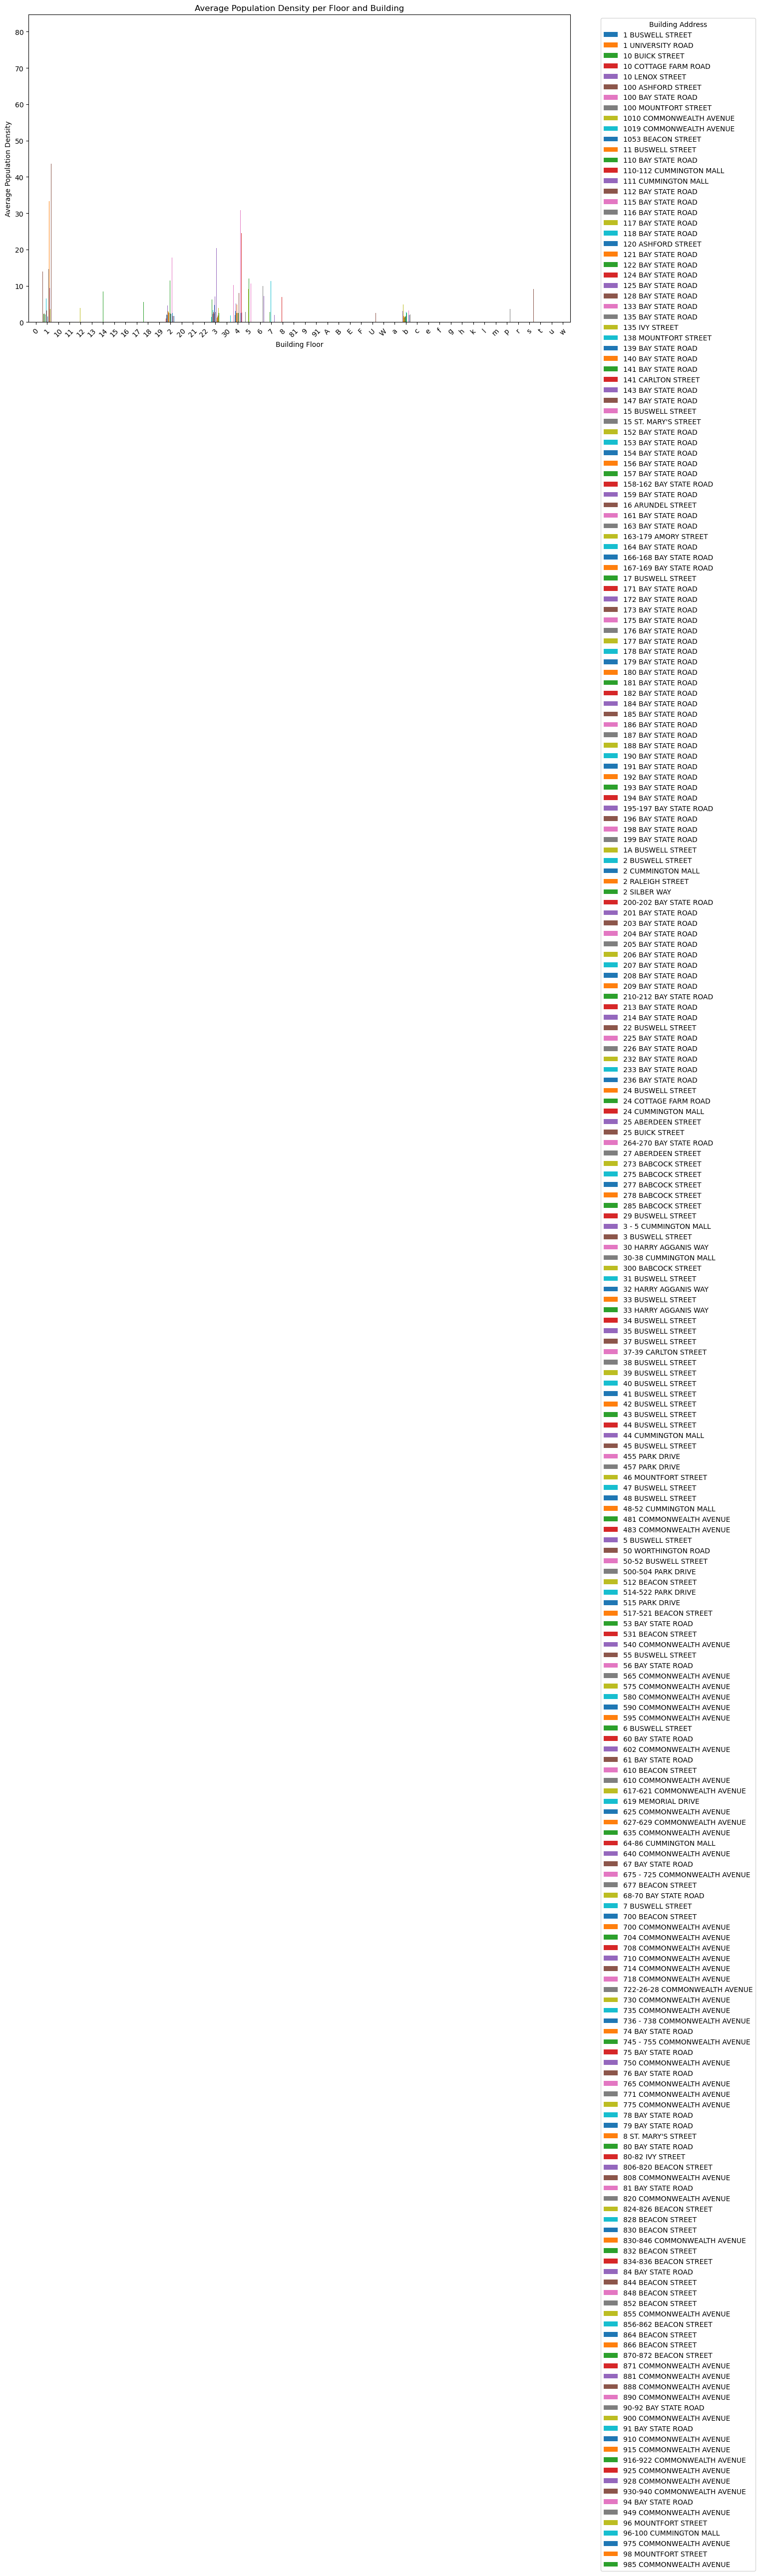

In [4]:
# Step 1: Load your CSV data into a DataFrame
df = pd.read_csv('updated_densitymap_hourly_cleaned.csv')

# Ensure that 'density_cnt' is numeric
df['density_cnt'] = pd.to_numeric(df['density_cnt'], errors='coerce')

# Step 2: Group by both 'building_floor' and 'building_desc' and calculate the average 'density_cnt'
average_density_per_floor_and_building = df.groupby(['building_floor', 'building_desc'])['density_cnt'].mean().unstack(fill_value=0)

# Step 3: Plot the data
average_density_per_floor_and_building.plot(kind='bar', figsize=(14, 8), width=0.8)
plt.xlabel('Building Floor')
plt.ylabel('Average Population Density')
plt.title('Average Population Density per Floor and Building')
plt.xticks(rotation=45)
plt.legend(title='Building Address', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [3]:
average_density_per_floor_and_building = df.groupby(['building_floor', 'building_desc'])['density_cnt'].mean().reset_index()


print(average_density_per_floor_and_building)

     building_floor                  building_desc  density_cnt
0                 0                 135 IVY STREET     1.660798
1                 0              531 BEACON STREET     6.458052
2                 1               1 BUSWELL STREET     2.028651
3                 1              1 UNIVERSITY ROAD    51.585595
4                 1                10 BUICK STREET    34.685260
...             ...                            ...          ...
1153              s    930-940 COMMONWEALTH AVENUE     9.084290
1154              t  675 - 725 COMMONWEALTH AVENUE     9.155403
1155              u              844 BEACON STREET     7.887827
1156              u          870-872 BEACON STREET     4.379075
1157              w             140 BAY STATE ROAD    17.981919

[1158 rows x 3 columns]


Fun Interactive version of the population by floor and address

In [6]:


# Step 1: Load your CSV data into a DataFrame
df = pd.read_csv('updated_densitymap_hourly_cleaned.csv')

# Ensure 'density_cnt' is numeric
df['density_cnt'] = pd.to_numeric(df['density_cnt'], errors='coerce')

# Step 2: Group by both 'building_floor' and 'building_desc' and calculate the average 'density_cnt'
grouped_data = df.groupby(['building_floor', 'building_desc'])['density_cnt'].mean().reset_index()

# Step 3: Create an interactive plot
fig = px.bar(grouped_data, x='building_floor', y='density_cnt',
             color='building_desc', barmode='group',
             labels={'density_cnt': 'Average Population Density'},
             title='Average Population Density per Floor and Building Address')

fig.update_layout(xaxis_title='Building Floor', yaxis_title='Average Population Density',
                  legend_title='Building Address')
fig.update_xaxes(type='category')  # Treat floor numbers as categorical data

fig.show()

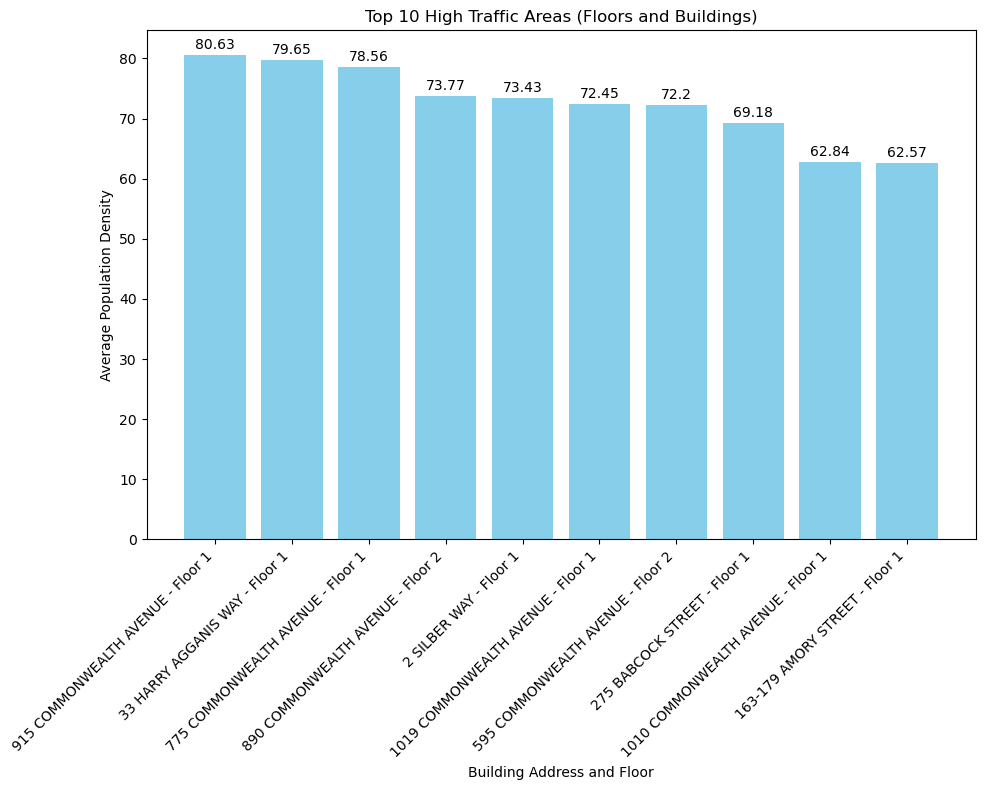

In [8]:
# Load your CSV data into a DataFrame
df = pd.read_csv('updated_densitymap_hourly_cleaned.csv')

# Ensure 'density_cnt' is numeric
df['density_cnt'] = pd.to_numeric(df['density_cnt'], errors='coerce')

# Group by both 'building_floor' and 'building_desc', calculate the average 'density_cnt'
average_density = df.groupby(['building_floor', 'building_desc'])['density_cnt'].mean().reset_index()

# Sort the results to get the top 10 floors and buildings with the highest average density
top_10_high_traffic = average_density.nlargest(10, 'density_cnt')

# Create a new column for plotting that combines building address and floor
top_10_high_traffic['building_floor_desc'] = top_10_high_traffic['building_desc'] + " - Floor " + top_10_high_traffic['building_floor'].astype(str)

# Plotting
plt.figure(figsize=(10, 8))
bars = plt.bar(top_10_high_traffic['building_floor_desc'], top_10_high_traffic['density_cnt'], color='skyblue')

# Adding value labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, round(yval, 2), ha='center', va='bottom')

plt.xticks(rotation=45, ha='right')
plt.xlabel('Building Address and Floor')
plt.ylabel('Average Population Density')
plt.title('Top 10 High Traffic Areas (Floors and Buildings)')
plt.tight_layout()  # Adjust layout to make room for the rotated x-axis labels
plt.show()

Part 2 Analysis of Historical Density CSV

C:\Users\Libra\AppData\Local\Temp\ipykernel_23392\3036139049.py:2: DtypeWarning:

Columns (2,7) have mixed types. Specify dtype option on import or set low_memory=False.



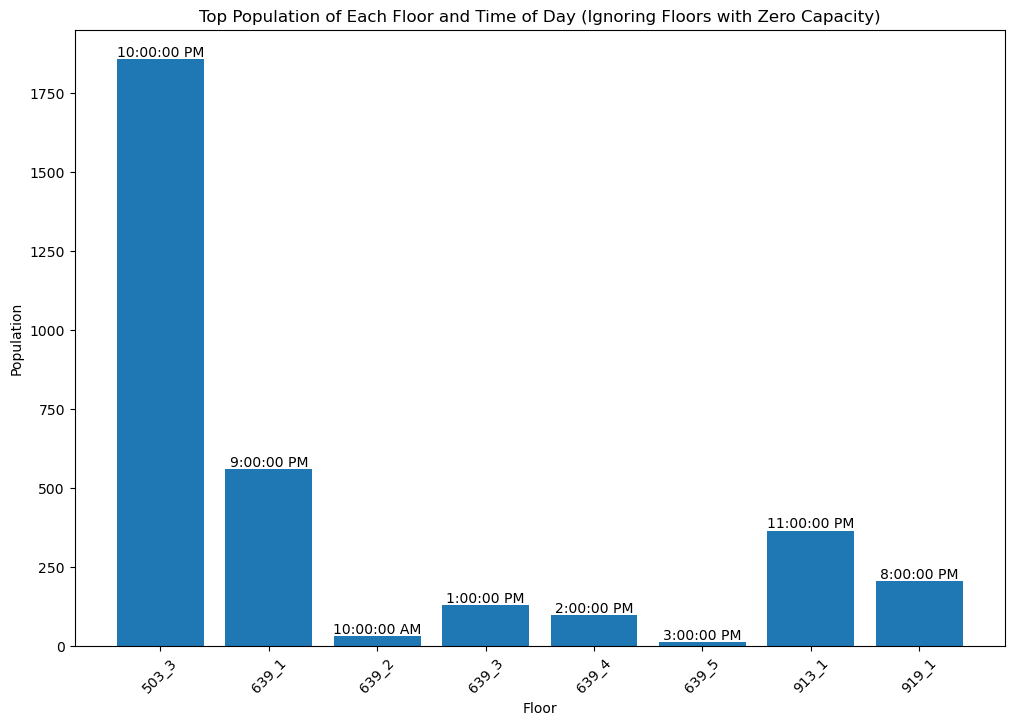

In [18]:
# Step 1: Read the CSV file
df = pd.read_csv('historical_density_8232020-10112023.xlsm - Export.csv')

df_filtered = df[df['Capacity'] > 0]

# Step 2: Process the Data (with filtering applied)
# Group by floor, find the maximum population for each filtered floor, and get the corresponding time
df_filtered = df[df['Capacity'] > 0]
grouped_df = df_filtered.groupby('Building_Floor').apply(lambda x: x.loc[x['Population'].idxmax()])
grouped_df.reset_index(drop=True, inplace=True)

# Step 3: Create the Bar Graph
plt.figure(figsize=(12, 8))
bars = plt.bar(grouped_df['Building_Floor'].astype(str), grouped_df['Population'])

# Annotate each bar with the time of day the top population occurred
for bar, hour in zip(bars, grouped_df['Hour 2']):
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval, f'{hour}', ha='center', va='bottom')

plt.xlabel('Floor')
plt.ylabel('Population')
plt.title('Top Population of Each Floor and Time of Day (Ignoring Floors with Zero Capacity)')
plt.xticks(rotation=45)  # Rotate floor labels if needed for better readability
plt.show()

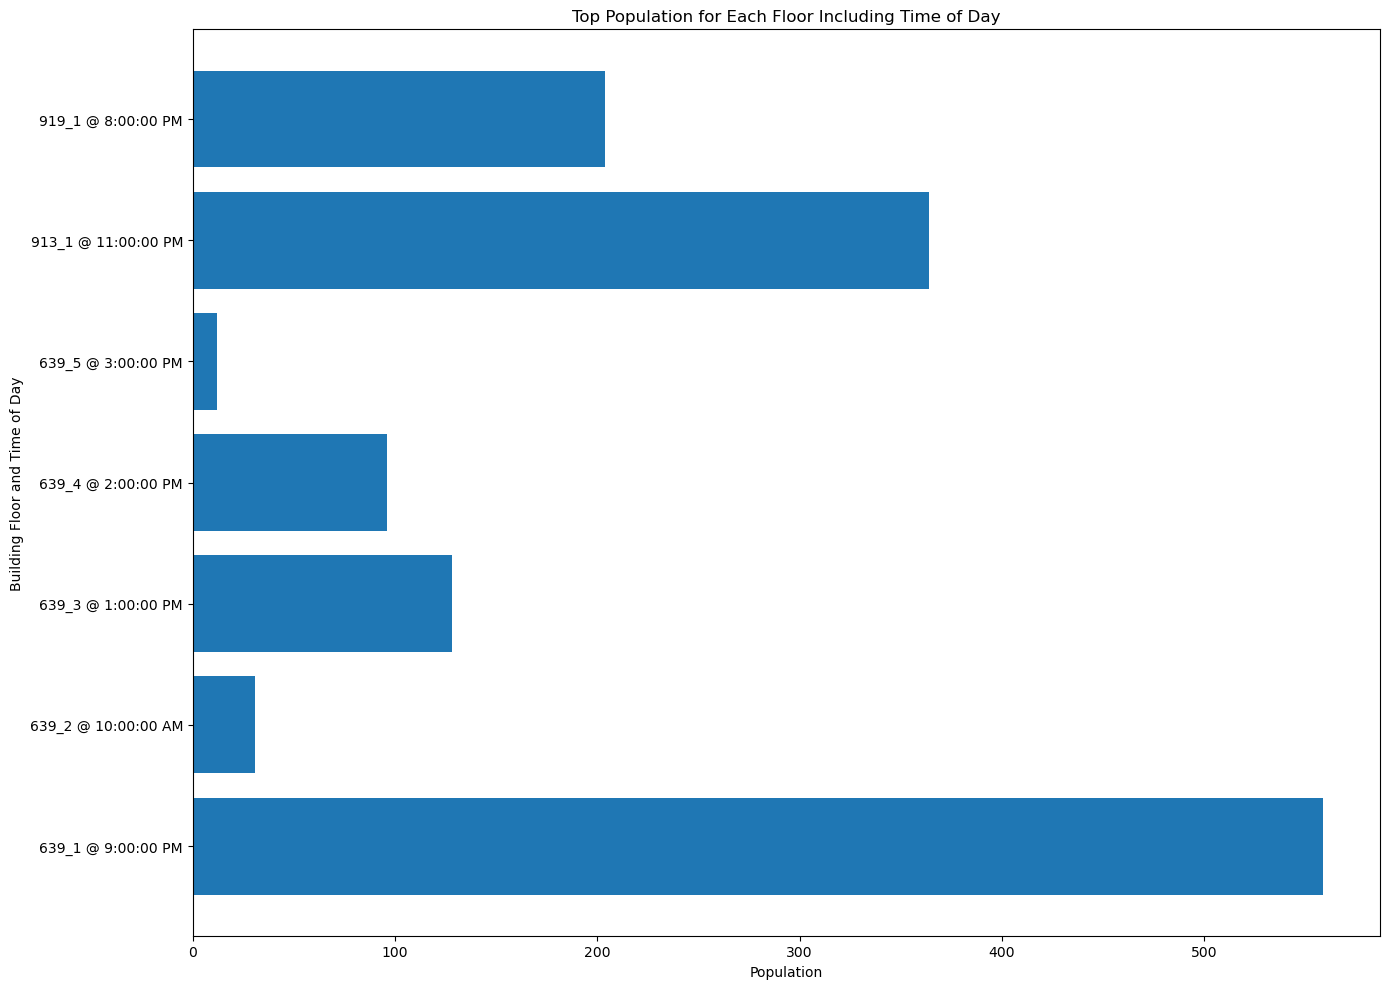

In [19]:
# Exclude floors with a capacity of zero and the specified floor "503_3"
df_filtered = df[(df['Capacity'] > 0) & (df['Building_Floor'] != '503_3')]


# Now, we will identify the top population for each floor across all times, including time of day, without excluding any specific floors
max_population_for_each_floor_time_of_day = df_filtered.groupby(['building_code', 'Building_Floor', 'Hour 2']).agg({
    'Population': 'max',
}).reset_index()

# Since we want the top population for each floor, we sort by Building_Floor and Population
sorted_population_for_each_floor_time_of_day = max_population_for_each_floor_time_of_day.sort_values(['Building_Floor', 'Population'], ascending=[True, False])

# Displaying the top entry for each floor which represents the time with the highest population
top_population_for_each_floor = sorted_population_for_each_floor_time_of_day.groupby(['Building_Floor']).first().reset_index()

# Plot
fig, ax = plt.subplots(figsize=(14, 10))

ax.barh(top_population_for_each_floor['Building_Floor'] + " @ " + top_population_for_each_floor['Hour 2'], top_population_for_each_floor['Population'])
ax.set_title('Top Population for Each Floor Including Time of Day')
ax.set_xlabel('Population')
ax.set_ylabel('Building Floor and Time of Day')

plt.tight_layout()
plt.show()



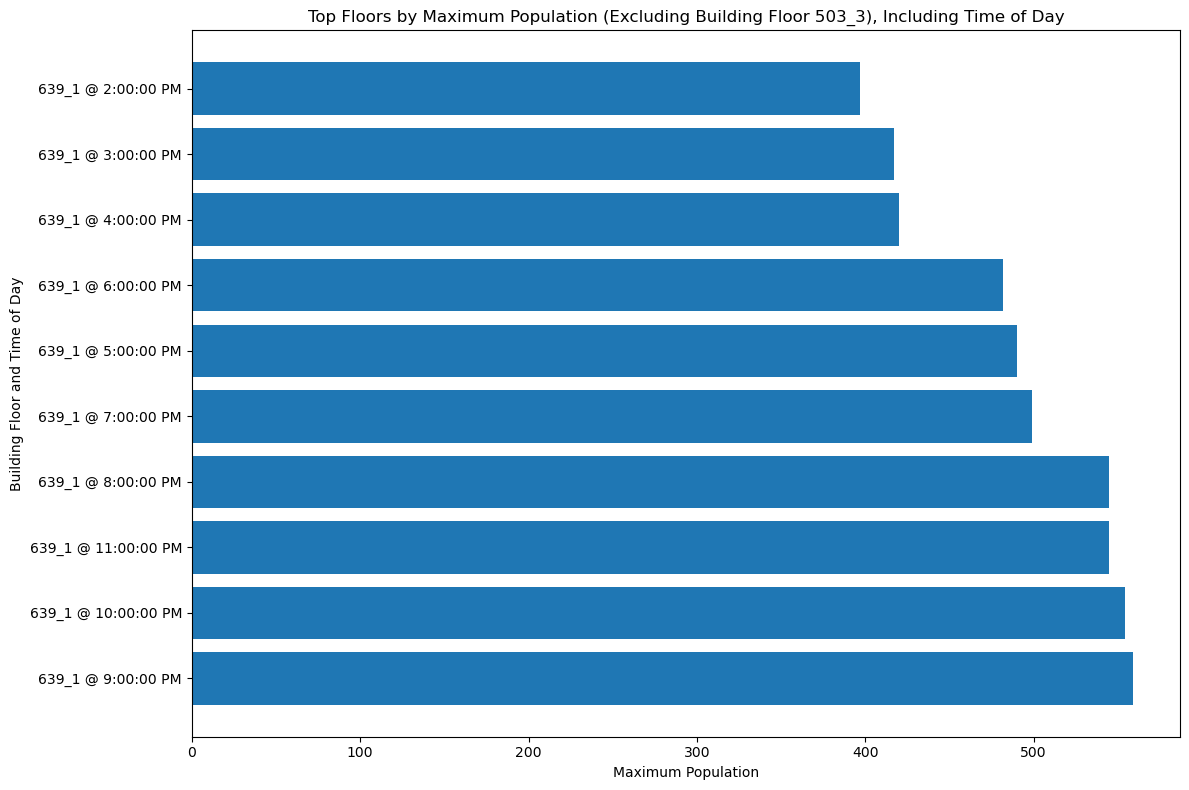

In [20]:
# Exclude building floor 503_3 and entries with a capacity of 0
df_filtered_excluding_503_3 = df[(df['Building_Floor'] != '503_3') & (df['Capacity'] > 0)]

# Repeat the analysis excluding building floor 503_3
max_population_time_of_day_excluding_503_3 = df_filtered_excluding_503_3.groupby(['building_code', 'Building_Floor', 'Hour 2']).agg({
    'Population': 'max',
}).reset_index()

# Identify floors that see the most population (Top 10 for visualization purposes)
top_floors_by_population_excluding_503_3 = max_population_time_of_day_excluding_503_3.nlargest(10, 'Population')

# Plot
fig, ax = plt.subplots(figsize=(12, 8))

ax.barh(top_floors_by_population_excluding_503_3['Building_Floor'] + " @ " + top_floors_by_population_excluding_503_3['Hour 2'], top_floors_by_population_excluding_503_3['Population'])
ax.set_title('Top Floors by Maximum Population (Excluding Building Floor 503_3), Including Time of Day')
ax.set_xlabel('Maximum Population')
ax.set_ylabel('Building Floor and Time of Day')

plt.tight_layout()
plt.show()



C:\Users\Libra\AppData\Local\Temp\ipykernel_23392\60068683.py:20: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



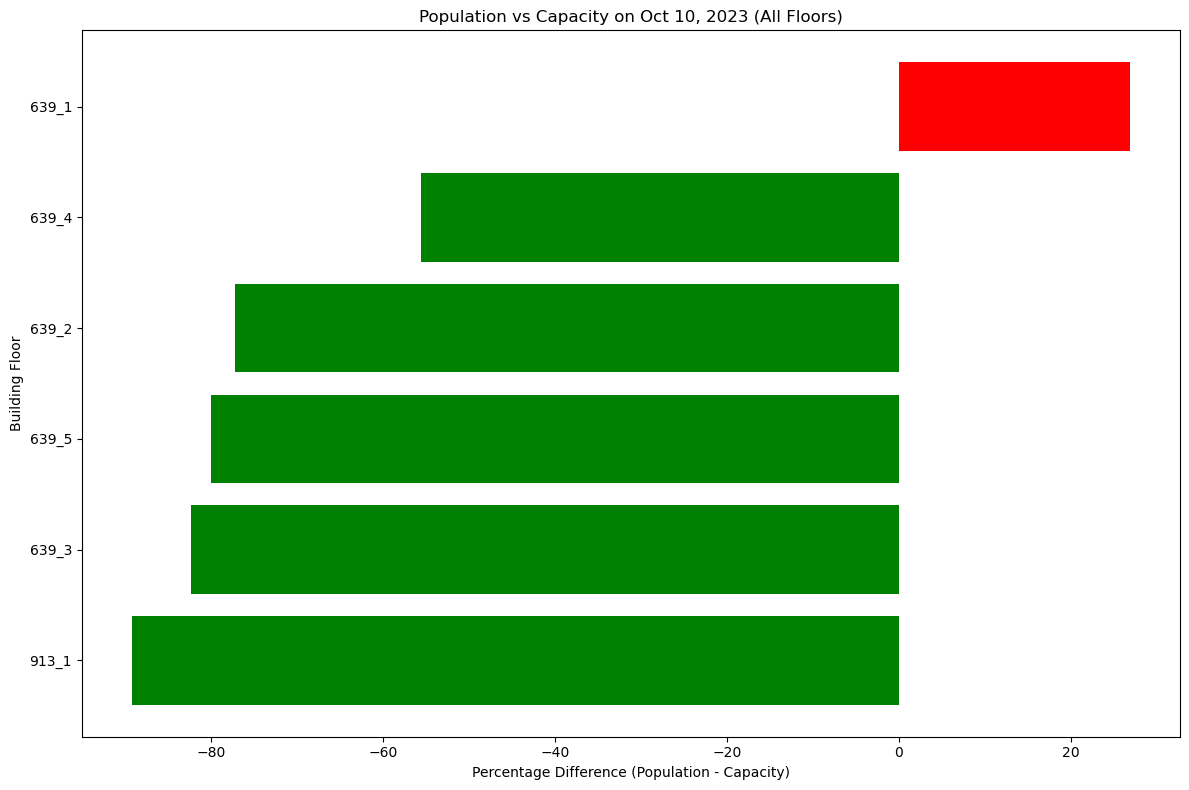

In [22]:
# Plot for all floors, not just those exceeding capacity

# Convert `date` column to datetime
df['date'] = pd.to_datetime(df['date'], errors='coerce')

# Filter for October 10, 2023
oct_10_2023_data = df[df['date'] == '2023-10-10']

# Group by building_code and Building_Floor and take the max Population for each group
max_population_by_floor = oct_10_2023_data.groupby(['building_code', 'Building_Floor']).agg({
    'Population': 'max',
    # Taking the first instance of Capacity as it should be constant for each building floor
    'Capacity': 'first' 
}).reset_index()

# Filter out entries where Capacity is 0
valid_capacity_data = max_population_by_floor[max_population_by_floor['Capacity'] > 0]

# Calculate the percentage by which the population exceeds the capacity
valid_capacity_data['Exceed_Percentage'] = ((valid_capacity_data['Population'] - valid_capacity_data['Capacity']) / valid_capacity_data['Capacity']) * 100

# Sorting the data for a cleaner plot
all_floors_sorted = valid_capacity_data.sort_values('Exceed_Percentage', ascending=True)

fig, ax = plt.subplots(figsize=(12, 8))

# Using a different color for floors not exceeding capacity
colors = ['green' if x <= 0 else 'red' for x in all_floors_sorted['Exceed_Percentage']]

ax.barh(all_floors_sorted['Building_Floor'], all_floors_sorted['Exceed_Percentage'], color=colors)
ax.set_title('Population vs Capacity on Oct 10, 2023 (All Floors)')
ax.set_xlabel('Percentage Difference (Population - Capacity)')
ax.set_ylabel('Building Floor')

plt.tight_layout()
plt.show()
